# Notebook 07 — Final Training and the Held-Out Test Set

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 07 of 12

---

> ### The test set is opened once, here, and never again
>
> The 98 test eggs were sealed in notebook 02 and have not been touched since. Every choice made
> between then and now — crop variant, augmentation policy, backbone, formulation, metadata
> fusion — was made on development data alone. **After this notebook runs, nothing may be tuned.**
> If a result here is disappointing, it is reported as it is. Going back to adjust and re-testing
> would turn the test set into a validation set and invalidate the entire evaluation.

### The configuration being frozen, and why

| decision | choice | evidence |
|---|---|---|
| crop variant | neutral fill | nb 02: 0.346 residual leak vs 0.384 for interior, and 100 % crack retention vs 31–48 % |
| augmentation | medium | nb 03: lowest residual leak among policies keeping ≥ 85 % of cracks above the contrast floor |
| resolution | 384 px | nb 01 retention curve; nb 05 VRAM measurements |
| backbone | EfficientNet-B0 | nb 05 Stage A, tied with ConvNeXt-Tiny at a seventh of the parameters |
| **formulation** | **multitask_seg** | see below |
| metadata fusion | **none** | nb 06: paired difference −0.0046 ± 0.0420 on pattern classification, a confirmed null |

**On the formulation.** Stage B ranked `hierarchical` highest at 0.7778 ± 0.0341, with
`multitask_seg` at 0.7688 ± 0.0227. The paired difference is +0.0089 ± 0.0147 — a tie, not a win.
Four reasons decide it for `multitask_seg`:

1. it is **one model, not two**, which halves inference cost and matters for the edge-deployment
   argument in Chapter 6;
2. it had the **lowest fold-to-fold variance of any configuration tested**, 0.0227 against 0.0341;
3. it produces a **crack localisation map**, which Objective 3 claims and notebook 09 must validate
   against the annotation polygons — the hierarchical model produces nothing to validate;
4. notebook 05d showed that **restricting the image to the crack region raises macro F1 from 0.743
   to 0.766**, so a backbone supervised to attend to crack pixels is the formulation most aligned
   with where the evidence actually lives.

Choosing the statistically tied option on deployment and explainability grounds, and saying so, is
a Chapter 4 design decision rather than a concession.

### What this notebook produces

Training on **all 554 development eggs** with no validation split — the epoch budget comes from the
cross-validation runs, so no test information is used to decide when to stop. Three seeds, because a
single run is not a result. Then one pass over the 98 test eggs, with every prediction saved for
notebook 08 to analyse. The runner-up is trained identically so that notebook 08 can run McNemar's
test against a real competitor rather than against a straw man.

---
## 0. Configuration

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"E:\Degree\Final Research\Egg_Crack_Dataset\Eggshell-Diagnostic-Research\Artefact"

SELECTED   = {"backbone": "efficientnet_b0", "formulation": "multitask_seg", "age_mode": "none"}
RUNNER_UP  = {"backbone": "efficientnet_b0", "formulation": "single4", "age_mode": "none"}
SEEDS      = [42, 43, 44]

CACHE_VARIANT = "neutral_fill"; CACHE_SIDE = 448; TRAIN_SIDE = 384
POLICY = "medium"; EFFECTIVE_BATCH = 32; NUM_WORKERS = 4
PHYS_BATCH = {"multitask_seg": 24, "single4": 32, "multitask": 32}
EPOCH_FALLBACK = 32          # used only if the CV epoch counts cannot be read

RUN_FINAL_TRAINING = False
OPEN_TEST_SET      = True   # deliberately separate: training can be re-run, this cannot

In [9]:
import sys, json, time, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, average_precision_score)

from common import project_config as CFG
from common.data import EggDataset, build_crack_masks, make_loader, class_weights
from common.engine import TrainConfig, train_fold, predict, append_run
from common.models import build_model, count_parameters

warnings.filterwarnings("ignore"); CFG.seed_everything()
STAGE = "07_final_and_test"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PRED_DIR = OUT / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)
MODELS = CFG.MODELS_DIR / "final"; MODELS.mkdir(parents=True, exist_ok=True)
PROC = CFG.DATA_DIR / "processed"; RUNS_CSV = CFG.RESULTS_DIR / "runs.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available(): torch.backends.cudnn.benchmark = True

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
CACHE_PATH = PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy"
y4 = splits["label4"].map(CFG.LABEL4_TO_IDX).to_numpy(dtype=np.int64)
y2 = splits["is_cracked"].to_numpy(dtype=np.int64)
ypat = np.where(y4 > 0, y4 - 1, -100).astype(np.int64)
age = splits["age_class"].map(CFG.AGE_TO_IDX).to_numpy(dtype=np.int64)
LABELS = {"y4": y4, "y2": y2, "ypat": ypat, "age": age}
MASKS = build_crack_masks(splits["crack_region"].tolist(), TRAIN_SIDE)
ALL4 = [0, 1, 2, 3]
def macro4(yt, yp): return float(f1_score(yt, yp, labels=ALL4, average="macro", zero_division=0))

DEV = splits.index[splits["split"].eq("dev")].to_numpy()
TEST = splits.index[splits["split"].eq("test")].to_numpy()
print(f"development {len(DEV)} eggs  |  TEST {len(TEST)} eggs (sealed since notebook 02)")
print("test class counts:",
      splits.loc[TEST, "label4"].value_counts().reindex(CFG.LABEL4).to_dict())
print("test age counts  :",
      splits.loc[TEST, "age_class"].value_counts().to_dict())

development 554 eggs  |  TEST 98 eggs (sealed since notebook 02)
test class counts: {'Intact': 47, 'Hairline': 22, 'Star': 11, 'Network': 18}
test age counts  : {'Late lay': 35, 'Early lay': 32, 'Peak production': 31}


---
## 1. Epoch budget from cross-validation

Training on all development data means there is no validation split to stop on. Taking the epoch
count from the cross-validation runs keeps the decision inside the development data, where it
belongs. The budget is scaled up slightly because the final model sees about 25 % more data than
any individual fold did.

In [10]:
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
def epoch_budget(cfgd):
    if not len(runs) or "epochs_run" not in runs.columns:
        return EPOCH_FALLBACK
    m = runs[(runs.get("tag", "").astype(str).str.startswith("stageB"))
             & (runs["backbone"] == cfgd["backbone"])
             & (runs["formulation"] == cfgd["formulation"])]
    v = pd.to_numeric(m["epochs_run"], errors="coerce").dropna()
    if not len(v):
        return EPOCH_FALLBACK
    return int(round(float(np.median(v)) * (len(DEV) / (len(DEV) * 0.8))))

BUDGET = {k["formulation"]: epoch_budget(k) for k in (SELECTED, RUNNER_UP)}
print("epoch budget taken from the Stage B cross-validation runs:")
for k, v in BUDGET.items():
    print(f"   {k:<16s} {v} epochs")
print("\nNo test data influenced this choice.")

epoch budget taken from the Stage B cross-validation runs:
   multitask_seg    32 epochs
   single4          32 epochs

No test data influenced this choice.


---
## 2. Train the final models on all development data

In [11]:
def train_final(cfgd, seed):
    form = cfgd["formulation"]
    batch = PHYS_BATCH.get(form, 24)
    ckpt = MODELS / f"final_{cfgd['backbone']}_{form}_seed{seed}.pt"
    if ckpt.exists():
        print(f"  seed {seed}: checkpoint exists, skipping")
        return ckpt
    cfg = TrainConfig(backbone=cfgd["backbone"], formulation=form, n_out=4, policy=POLICY,
                      train_side=TRAIN_SIDE, epochs=BUDGET[form], physical_batch=batch,
                      effective_batch=EFFECTIVE_BATCH, patience=10 ** 6,  # no early stopping
                      num_workers=NUM_WORKERS, seed=seed, age_mode=cfgd["age_mode"],
                      tag="final")
    want_mask = form == "multitask_seg"
    ds_tr = EggDataset(CACHE_PATH, DEV, LABELS, TRAIN_SIDE, policy=POLICY,
                       masks=MASKS if want_mask else None)
    # the "validation" loader here is the training data itself; it only drives the progress
    # printout, never a stopping decision, because patience is effectively infinite
    ltr = make_loader(ds_tr, batch, True, NUM_WORKERS)
    lmon = make_loader(EggDataset(CACHE_PATH, DEV[:120], LABELS, TRAIN_SIDE, policy=None,
                                  masks=MASKS if want_mask else None),
                       batch, False, NUM_WORKERS)
    w4 = class_weights(y4[DEV], 4); w2 = class_weights(y2[DEV], 2)
    wp = class_weights(ypat[DEV][ypat[DEV] >= 0], 3)
    t0 = time.time()
    m, _, state = train_fold(cfg, ltr, lmon, device, w4, w2, wp, verbose=False)
    torch.save({"state_dict": state, "config": cfg.asdict(), "train_metrics": m}, ckpt)
    print(f"  seed {seed}: {BUDGET[form]} epochs in {(time.time()-t0)/60:.1f} min, "
          f"peak VRAM {m['peak_vram_gb']:.2f} GB -> {ckpt.name}")
    return ckpt

CKPTS = {}
if RUN_FINAL_TRAINING:
    for name, cfgd in [("selected", SELECTED), ("runner_up", RUNNER_UP)]:
        print(f"\n{'=' * 58}\n{name}: {cfgd['backbone']} + {cfgd['formulation']}\n{'=' * 58}")
        CKPTS[name] = [train_final(cfgd, s) for s in SEEDS]
else:
    for name, cfgd in [("selected", SELECTED), ("runner_up", RUNNER_UP)]:
        CKPTS[name] = [MODELS / f"final_{cfgd['backbone']}_{cfgd['formulation']}_seed{s}.pt"
                       for s in SEEDS]
    print("training not run; will use existing checkpoints if present")
    for n, v in CKPTS.items():
        print(f"  {n}: {sum(p.exists() for p in v)}/{len(v)} checkpoints present")

training not run; will use existing checkpoints if present
  selected: 3/3 checkpoints present
  runner_up: 3/3 checkpoints present


---
## 3. Open the test set

One pass. Every per-egg prediction and probability is written to disk for notebook 08, so the
analysis there needs no further inference and the test set is never loaded again.

In [12]:
def load_model(ckpt, cfgd):
    sd = torch.load(ckpt, map_location="cpu", weights_only=False)
    mdl = build_model(cfgd["backbone"], cfgd["formulation"], 4, pretrained=False,
                      age_mode=cfgd["age_mode"], img_size=TRAIN_SIDE)
    mdl.load_state_dict(sd["state_dict"]); mdl.to(device).eval()
    return mdl, sd["config"]

def test_predict(cfgd, ckpts, name):
    want_mask = cfgd["formulation"] == "multitask_seg"
    ds = EggDataset(CACHE_PATH, TEST, LABELS, TRAIN_SIDE, policy=None,
                    masks=MASKS if want_mask else None)
    loader = make_loader(ds, 16, False, NUM_WORKERS)
    probs = []
    for ck in ckpts:
        if not ck.exists():
            print(f"  missing {ck.name}"); continue
        mdl, cfgdict = load_model(ck, cfgd)
        cfg = TrainConfig(**{k: v for k, v in cfgdict.items() if k in TrainConfig().asdict()})
        p = predict(mdl, loader, device, cfg)
        if "logits" in p:
            lg = p["logits"]
        else:
            det = torch.softmax(torch.tensor(p["logits_det"]), 1).numpy()
            pat = torch.softmax(torch.tensor(p["logits_pat"]), 1).numpy()
            lg = np.column_stack([det[:, 0], det[:, 1:2] * pat])
            lg = np.log(np.clip(lg, 1e-9, None))
        order = np.argsort(p["idx"])
        probs.append(torch.softmax(torch.tensor(lg[order]), 1).numpy())
        del mdl; torch.cuda.empty_cache()
        idx_sorted = p["idx"][order]; yt4 = p["y4"][order]; yt2 = p["y2"][order]
    P = np.mean(probs, axis=0)
    np.savez(PRED_DIR / f"test_{name}.npz", idx=idx_sorted, y4=yt4, y2=yt2,
             prob=P, prob_per_seed=np.stack(probs))
    return idx_sorted, yt4, yt2, P, np.stack(probs)

if OPEN_TEST_SET:
    print("OPENING THE HELD-OUT TEST SET\n")
    RESULTS = {}
    for name, cfgd in [("selected", SELECTED), ("runner_up", RUNNER_UP)]:
        idx, yt4, yt2, P, PS = test_predict(cfgd, CKPTS[name], name)
        RESULTS[name] = dict(idx=idx, y4=yt4, y2=yt2, prob=P, per_seed=PS, cfg=cfgd)
        per_seed_f1 = [macro4(yt4, ps.argmax(1)) for ps in PS]
        yp = P.argmax(1)
        print(f"{name}: {cfgd['backbone']} + {cfgd['formulation']}")
        print(f"   per-seed macro F1 : {[round(v, 4) for v in per_seed_f1]}  "
              f"mean {np.mean(per_seed_f1):.4f} ± {np.std(per_seed_f1, ddof=1):.4f}")
        print(f"   seed ensemble     : {macro4(yt4, yp):.4f}")
        print(f"   binary macro F1   : "
              f"{f1_score(yt2, (yp > 0).astype(int), average='macro', zero_division=0):.4f}\n")
else:
    RESULTS = {}
    for name in ("selected", "runner_up"):
        f = PRED_DIR / f"test_{name}.npz"
        if f.exists():
            z = np.load(f)
            RESULTS[name] = dict(idx=z["idx"], y4=z["y4"], y2=z["y2"], prob=z["prob"],
                                 per_seed=z["prob_per_seed"],
                                 cfg=SELECTED if name == "selected" else RUNNER_UP)
    print("test set not opened in this run; loaded saved predictions"
          if RESULTS else "no test predictions available yet")

OPENING THE HELD-OUT TEST SET

selected: efficientnet_b0 + multitask_seg
   per-seed macro F1 : [0.794, 0.7724, 0.8098]  mean 0.7921 ± 0.0188
   seed ensemble     : 0.7942
   binary macro F1   : 0.9070

runner_up: efficientnet_b0 + single4
   per-seed macro F1 : [0.8251, 0.769, 0.7857]  mean 0.7933 ± 0.0288
   seed ensemble     : 0.8135
   binary macro F1   : 0.9065



---
## 4. Headline test results

              precision    recall  f1-score   support

      Intact      0.975     0.830     0.897        47
    Hairline      0.643     0.818     0.720        22
        Star      0.750     0.818     0.783        11
     Network      0.778     0.778     0.778        18

    accuracy                          0.816        98
   macro avg      0.786     0.811     0.794        98
weighted avg      0.839     0.816     0.822        98

{
  "four_class_macro_f1": 0.7942,
  "four_class_balanced_acc": 0.811,
  "four_class_accuracy": 0.8163,
  "binary_macro_f1": 0.907,
  "binary_roc_auc": 0.9854,
  "binary_pr_auc": 0.9873,
  "n_test": 98,
  "per_seed_macro_f1": [
    0.794,
    0.7724,
    0.8098
  ],
  "seed_sd": 0.0188
}


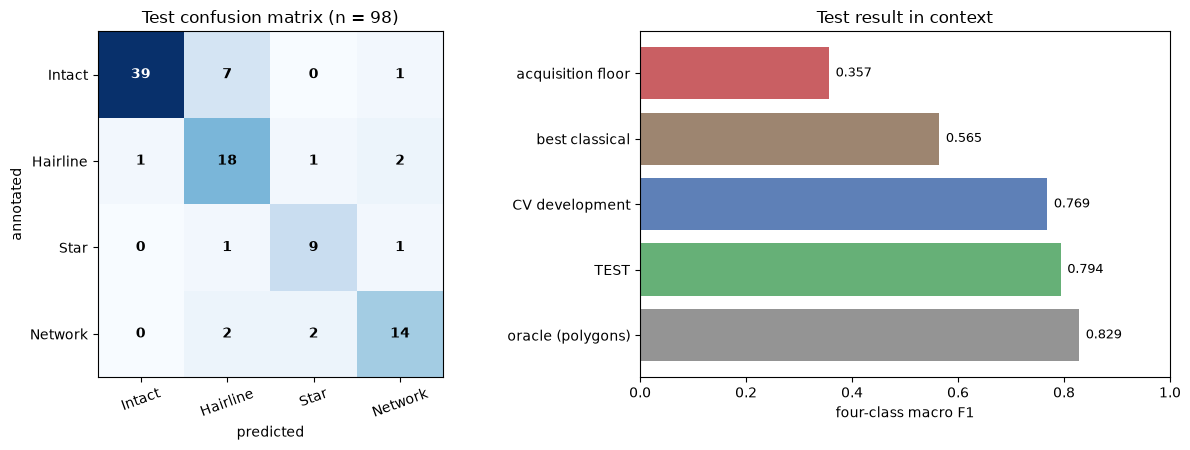

In [13]:
if "selected" in RESULTS:
    R = RESULTS["selected"]
    yt4, yt2, P = R["y4"], R["y2"], R["prob"]
    yp = P.argmax(1); p_cracked = 1.0 - P[:, 0]

    rep = classification_report(yt4, yp, labels=ALL4, target_names=CFG.LABEL4,
                                digits=3, zero_division=0, output_dict=True)
    rep_df = pd.DataFrame(rep).T.round(3)
    rep_df.to_csv(TAB_DIR / "t01_test_classification_report.csv")
    print(classification_report(yt4, yp, labels=ALL4, target_names=CFG.LABEL4,
                                digits=3, zero_division=0))

    head = {
        "four_class_macro_f1": round(macro4(yt4, yp), 4),
        "four_class_balanced_acc": round(float(balanced_accuracy_score(yt4, yp)), 4),
        "four_class_accuracy": round(float((yt4 == yp).mean()), 4),
        "binary_macro_f1": round(float(f1_score(yt2, (yp > 0).astype(int), average="macro",
                                                zero_division=0)), 4),
        "binary_roc_auc": round(float(roc_auc_score(yt2, p_cracked)), 4),
        "binary_pr_auc": round(float(average_precision_score(yt2, p_cracked)), 4),
        "n_test": int(len(yt4)),
    }
    per_seed = [macro4(yt4, ps.argmax(1)) for ps in R["per_seed"]]
    head["per_seed_macro_f1"] = [round(v, 4) for v in per_seed]
    head["seed_sd"] = round(float(np.std(per_seed, ddof=1)), 4)
    print(json.dumps(head, indent=2))

    cm = confusion_matrix(yt4, yp, labels=ALL4)
    pd.DataFrame(cm, index=CFG.LABEL4, columns=CFG.LABEL4).to_csv(
        TAB_DIR / "t02_test_confusion_matrix.csv")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    ax = axes[0]
    im = ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontweight="bold",
                    color="white" if cm[i, j] > cm.max() * 0.6 else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(CFG.LABEL4, rotation=20)
    ax.set_yticks(range(4)); ax.set_yticklabels(CFG.LABEL4)
    ax.set_xlabel("predicted"); ax.set_ylabel("annotated"); ax.grid(False)
    ax.set_title(f"Test confusion matrix (n = {len(yt4)})")

    ax = axes[1]
    bars = {"acquisition floor": 0.357, "best classical": 0.565,
            "CV development": 0.7688, "TEST": head["four_class_macro_f1"],
            "oracle (polygons)": 0.829}
    cols = ["#C44E52", "#937860", "#4C72B0", "#55A868", "#888888"]
    ax.barh(list(bars), list(bars.values()), color=cols, alpha=0.9)
    for i, v in enumerate(bars.values()):
        ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 1.0); ax.set_xlabel("four-class macro F1")
    ax.set_title("Test result in context")
    fig.tight_layout(); fig.savefig(FIG_DIR / "01_test_results.png", bbox_inches="tight")
    plt.show()

In [14]:
# --- deployment measurements for Section 5.5 -----------------------------
if "selected" in RESULTS and CKPTS["selected"][0].exists():
    mdl, _ = load_model(CKPTS["selected"][0], SELECTED)
    x = torch.randn(1, 3, TRAIN_SIDE, TRAIN_SIDE, device=device)
    with torch.no_grad():
        for _ in range(10): mdl(x)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(50): mdl(x)
        if torch.cuda.is_available(): torch.cuda.synchronize()
    lat = (time.time() - t0) / 50 * 1000
    size_mb = CKPTS["selected"][0].stat().st_size / 1e6
    deploy = {"params_m": round(count_parameters(mdl) / 1e6, 2),
              "latency_ms_single_image": round(lat, 2),
              "checkpoint_mb": round(size_mb, 1),
              "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
    print(json.dumps(deploy, indent=2))
    del mdl; torch.cuda.empty_cache()
else:
    deploy = {}

S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "selected": SELECTED, "runner_up": RUNNER_UP, "seeds": SEEDS,
     "epoch_budget": BUDGET, "headline": head if "selected" in RESULTS else {},
     "deployment": deploy}
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "test_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 07 DIGEST -- FINAL MODEL AND HELD-OUT TEST", "=" * 70,
     f"generated: {S['generated_at']}",
     f"model: {SELECTED['backbone']} + {SELECTED['formulation']}, age_mode={SELECTED['age_mode']}",
     f"trained on all {len(DEV)} development eggs, {SEEDS} seeds, "
     f"{BUDGET.get(SELECTED['formulation'])} epochs", ""]
if "selected" in RESULTS:
    for k, v in head.items():
        L.append(f"   {k:<26s} {v}")
if deploy:
    L += [""] + [f"   {k:<26s} {v}" for k, v in deploy.items()]
L.append("=" * 70)
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

{
  "params_m": 3.67,
  "latency_ms_single_image": 4.91,
  "checkpoint_mb": 15.0,
  "gpu": "NVIDIA GeForce RTX 5070"
}
NOTEBOOK 07 DIGEST -- FINAL MODEL AND HELD-OUT TEST
generated: 2026-10-09T17:15:41
model: efficientnet_b0 + multitask_seg, age_mode=none
trained on all 554 development eggs, [42, 43, 44] seeds, 32 epochs

   four_class_macro_f1        0.7942
   four_class_balanced_acc    0.811
   four_class_accuracy        0.8163
   binary_macro_f1            0.907
   binary_roc_auc             0.9854
   binary_pr_auc              0.9873
   n_test                     98
   per_seed_macro_f1          [0.794, 0.7724, 0.8098]
   seed_sd                    0.0188

   params_m                   3.67
   latency_ms_single_image    4.91
   checkpoint_mb              15.0
   gpu                        NVIDIA GeForce RTX 5070
